In [8]:
import numpy as np
import random
import seaborn as sns
from matplotlib import pyplot as plt

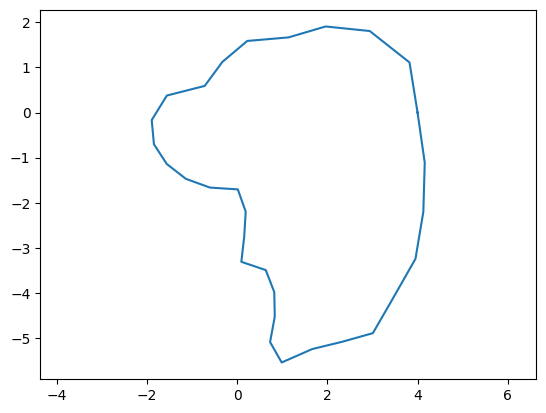

In [321]:
import numpy as np
import matplotlib.pyplot as plt


def generate_walk(
        n: int, radius: float,
        max_turn_deg: float,
        turn_restoring: float,
        closing_sharpness: float,
        max_offset_deg: float,
        seed: int = 1,
        close_end: bool = True
):
    np.random.seed(seed)
    step = 2 * np.pi * radius / n
    pos = np.zeros((n + 1, 2))
    pos[0] = [radius, 0]
    offset = 0.0

    for i in range(n):
        progress = (i + 1) / n
        guide = 2 * np.pi * progress + np.pi / 2
        restoring = turn_restoring + \
            (1 - turn_restoring) * progress ** closing_sharpness

        offset += np.radians(np.random.uniform(-max_turn_deg, max_turn_deg))
        offset -= restoring * offset
        offset = np.clip(offset, -np.radians(max_offset_deg),
                         np.radians(max_offset_deg))

        heading = guide + offset
        pos[i + 1] = pos[i] + step * \
            np.array([np.cos(heading), np.sin(heading)])

    if close_end:
        diff = pos[0] - pos[-1]
        pos += diff * np.linspace(0, 1, n + 1)[:, np.newaxis]


    return pos


pos = generate_walk(30, 4, 80, 0.1, 3, 80, seed=np.random.randint(0, 100))
plt.plot(pos[:, 0], pos[:, 1])
plt.axis("equal")
plt.show()